# COVID-19 Data Analysis & Death Prediction using Python, SQL, ML and DL
**Big Data – Continuous Assessment Project**

Dataset: Our World in Data COVID-19 dataset (CC BY 4.0) — https://github.com/owid/covid-19-data

Tech stack: Python · pandas · NumPy · SQLite (SQL) · scikit-learn (ML) · TensorFlow/Keras (DL) · Matplotlib

Steps: 1) Load data in chunks → 2) Data-quality check → 3) Clean → 4) Optimise memory → 5) Store in SQL database → 6) SQL analysis → 7) Charts → 8) ML & DL models to predict next week's deaths

In [1]:
import os, time, json, sqlite3
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf

DATA = "data/owid-covid-data.csv"   # download link in README
URL = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
if not os.path.exists(DATA):
    os.makedirs("data", exist_ok=True); pd.read_csv(URL).to_csv(DATA, index=False)
os.makedirs("figs", exist_ok=True); os.makedirs("output", exist_ok=True)
R = {}   # all results go here (used in report & slides)
BLUE, ORANGE, AQUA, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": "#e4e3df"})
print("pandas", pd.__version__, "| tensorflow", tf.__version__, "| sqlite", sqlite3.sqlite_version)

pandas 3.0.6 | tensorflow 2.21.0 | sqlite 3.45.1


## 1. Load the data (in chunks)
The file is ~98 MB. To show how large files are handled without loading everything at once, we first read it in **chunks of 100,000 rows**, then load it fully for analysis.

In [2]:
t = time.time()
n_rows, n_chunks = 0, 0
for chunk in pd.read_csv(DATA, chunksize=100_000):
    n_rows += len(chunk); n_chunks += 1
R["chunk_read_s"] = round(time.time() - t, 2); R["n_chunks"] = n_chunks
print(f"Read {n_rows:,} rows in {n_chunks} chunks in {R['chunk_read_s']} s")

t = time.time()
raw = pd.read_csv(DATA, parse_dates=["date"])
R["load_s"] = round(time.time() - t, 2)
R["raw_rows"], R["raw_cols"] = raw.shape
R["raw_file_mb"] = round(os.path.getsize(DATA) / 1e6, 1)
R["n_locations"] = raw.location.nunique()
R["date_min"], R["date_max"] = str(raw.date.min().date()), str(raw.date.max().date())
print(raw.shape, R["raw_file_mb"], "MB |", R["n_locations"], "locations |", R["date_min"], "to", R["date_max"])
raw.head()

Read 429,435 rows in 5 chunks in 1.13 s


(429435, 67) 98.4 MB | 255 locations | 2020-01-01 to 2024-08-14


,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN


## 2. Data-quality check

In [3]:
null_pct = (raw.isna().mean() * 100).round(1)
R["null_pct"] = null_pct.to_dict()
R["cols_over_50_null"] = int((null_pct > 50).sum())
R["aggregate_rows"] = int(raw.iso_code.str.startswith("OWID_").sum())
R["duplicate_rows"] = int(raw.duplicated(["iso_code", "date"]).sum())
R["dtype_counts"] = raw.dtypes.astype(str).value_counts().to_dict()
print("Columns >50% empty:", R["cols_over_50_null"], "of", R["raw_cols"])
print("Aggregate rows (World, continents, income groups):", R["aggregate_rows"])
print("Duplicate (iso_code, date) rows:", R["duplicate_rows"])
print("Negative new_cases:", int((raw.new_cases < 0).sum()), "| negative new_deaths:", int((raw.new_deaths < 0).sum()))
null_pct.sort_values(ascending=False).head(10)

Columns >50% empty: 38 of 67
Aggregate rows (World, continents, income groups): 34124
Duplicate (iso_code, date) rows: 7770
Negative new_cases: 0 | negative new_deaths: 0


weekly_icu_admissions                      97.4
weekly_icu_admissions_per_million          97.4
excess_mortality                           96.9
excess_mortality_cumulative_absolute       96.9
excess_mortality_cumulative                96.9
excess_mortality_cumulative_per_million    96.9
weekly_hosp_admissions                     94.3
weekly_hosp_admissions_per_million         94.3
icu_patients_per_million                   90.9
icu_patients                               90.9
dtype: float64

## 3. Clean the data

In [4]:
keep = ["iso_code", "continent", "location", "date", "new_cases", "new_deaths", "total_cases", "total_deaths",
        "total_deaths_per_million", "new_cases_smoothed", "people_fully_vaccinated_per_hundred",
        "population", "median_age", "gdp_per_capita", "hospital_beds_per_thousand"]
df = (raw[keep]
      .loc[lambda d: ~d.iso_code.str.startswith("OWID_")]      # remove World/continent rows
      .loc[lambda d: d.continent.notna()]
      .drop_duplicates(["iso_code", "date"]))                   # remove duplicate rows
for c in ["new_cases", "new_deaths"]:
    df[c] = df[c].clip(lower=0).fillna(0)                       # no negative counts, nulls -> 0
df["year"] = df.date.dt.year
R["clean_rows"], R["clean_countries"] = len(df), df.iso_code.nunique()
print(f"{R['raw_rows']:,} -> {R['clean_rows']:,} rows | {R['n_locations']} -> {R['clean_countries']} locations")

429,435 -> 393,903 rows | 255 -> 237 locations


## 4. Reduce memory (dtype optimisation)
Changing text columns to `category` and numbers to smaller types (`float32`) lets the same data use much less RAM — a simple Big Data technique.

In [5]:
mem_before = raw.memory_usage(deep=True).sum() / 1e6
small = df.copy()
for c in ["iso_code", "continent", "location"]:
    small[c] = small[c].astype("category")
for c in small.select_dtypes("float64").columns:
    small[c] = small[c].astype("float32")
small["year"] = small["year"].astype("int16")
mem_clean = df.memory_usage(deep=True).sum() / 1e6
mem_after = small.memory_usage(deep=True).sum() / 1e6
R["mem_raw_mb"], R["mem_clean_mb"], R["mem_opt_mb"] = round(mem_before, 1), round(mem_clean, 1), round(mem_after, 1)
print(f"Raw DataFrame: {mem_before:.1f} MB | cleaned: {mem_clean:.1f} MB | optimised: {mem_after:.1f} MB")

Raw DataFrame: 240.4 MB | cleaned: 59.9 MB | optimised: 28.0 MB


## 5. Store in a SQL database (SQLite)

In [6]:
DB = "output/covid.db"
if os.path.exists(DB): os.remove(DB)
con = sqlite3.connect(DB)
t = time.time()
out = df.copy(); out["date"] = out.date.dt.strftime("%Y-%m-%d")
out.to_sql("covid", con, index=False, chunksize=50_000)
R["sql_write_s"] = round(time.time() - t, 2)
R["db_mb"] = round(os.path.getsize(DB) / 1e6, 1)
print("rows in table:", con.execute("SELECT COUNT(*) FROM covid").fetchone()[0], "| db size", R["db_mb"], "MB")

# speed of a lookup query before and after adding an index
q = "SELECT date, new_cases, new_deaths FROM covid WHERE iso_code = 'IND' ORDER BY date"
def timeit(n=20):
    t = time.time()
    for _ in range(n): con.execute(q).fetchall()
    return (time.time() - t) / n * 1000
R["q_no_index_ms"] = round(timeit(), 2)
con.execute("CREATE INDEX idx_country_date ON covid(iso_code, date)")
R["q_index_ms"] = round(timeit(), 2)
print(f"Query without index: {R['q_no_index_ms']} ms | with index: {R['q_index_ms']} ms")

rows in table: 393903 | db size 37.3 MB


Query without index: 27.3 ms | with index: 1.2 ms


## 6. Analysis with SQL queries

In [7]:
yearly = pd.read_sql('''
    SELECT year, SUM(new_cases) AS cases, SUM(new_deaths) AS deaths,
           ROUND(100.0 * SUM(new_deaths) / SUM(new_cases), 2) AS cfr_pct
    FROM covid GROUP BY year ORDER BY year''', con)
R["yearly"] = yearly.to_dict("records")
yearly

,year,cases,deaths,cfr_pct
0,2020,80267309.0,1896289.0,2.36
1,2021,200183063.0,3547663.0,1.77
2,2022,423879722.0,1248913.0,0.29
3,2023,69236092.0,322630.0,0.47
4,2024,2063363.0,42258.0,2.05


In [8]:
monthly = pd.read_sql('''
    SELECT substr(date, 1, 7) AS month, SUM(new_cases) AS cases, SUM(new_deaths) AS deaths
    FROM covid GROUP BY month ORDER BY month''', con)
monthly["month"] = pd.to_datetime(monthly.month)
pk_c = monthly.loc[monthly.cases.idxmax()]; pk_d = monthly.loc[monthly.deaths.idxmax()]
R["peak_cases"] = {"month": pk_c.month.strftime("%B %Y"), "cases": int(pk_c.cases)}
R["peak_deaths"] = {"month": pk_d.month.strftime("%B %Y"), "deaths": int(pk_d.deaths)}
print(R["peak_cases"], R["peak_deaths"])

{'month': 'January 2022', 'cases': 94640059} {'month': 'January 2021', 'deaths': 483813}


In [9]:
# latest row of every country using a SQL window function (ROW_NUMBER)
latest_sql = '''
    WITH ranked AS (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY iso_code ORDER BY date DESC) AS rn
        FROM covid WHERE total_cases IS NOT NULL)
    SELECT iso_code, location, continent, total_cases, total_deaths, total_deaths_per_million, population
    FROM ranked WHERE rn = 1'''
latest = pd.read_sql(latest_sql, con)
R["world_total_cases"], R["world_total_deaths"] = int(latest.total_cases.sum()), int(latest.total_deaths.sum())

continent = pd.read_sql(f'''
    SELECT continent, SUM(total_cases) AS cases, SUM(total_deaths) AS deaths, SUM(population) AS pop,
           ROUND(SUM(total_deaths) * 1e6 / SUM(population)) AS deaths_per_million,
           ROUND(100.0 * SUM(total_deaths) / SUM(total_cases), 2) AS cfr_pct
    FROM ({latest_sql}) GROUP BY continent ORDER BY deaths_per_million DESC''', con)
R["continent"] = continent.to_dict("records")

top10 = pd.read_sql(f'''
    SELECT location, continent, ROUND(total_deaths_per_million) AS dpm
    FROM ({latest_sql}) WHERE population > 1000000 ORDER BY dpm DESC LIMIT 10''', con)
R["top10"] = top10.to_dict("records")
print(f"World: {R['world_total_cases']:,} cases, {R['world_total_deaths']:,} deaths")
continent

World: 775,592,504 cases, 7,053,920 deaths


,continent,cases,deaths,pop,deaths_per_million,cfr_pct
0,South America,68809418.0,1354187.0,436816679,3100.0,1.97
1,Europe,252642589.0,2099271.0,745629155,2815.0,0.83
2,North America,124492666.0,1671178.0,600323657,2784.0,1.34
3,Oceania,15003352.0,32918.0,45038907,731.0,0.22
4,Asia,301499099.0,1637249.0,4689377951,349.0,0.54
5,Africa,13145380.0,259117.0,1426160609,182.0,1.97


In [10]:
# month in which each country had its highest 7-day average of cases
peaks = pd.read_sql('''
    WITH r AS (SELECT location, date, ROW_NUMBER() OVER (PARTITION BY iso_code ORDER BY new_cases_smoothed DESC) AS rn
               FROM covid WHERE new_cases_smoothed IS NOT NULL)
    SELECT substr(date, 1, 7) AS peak_month, COUNT(*) AS countries FROM r WHERE rn = 1
    GROUP BY peak_month ORDER BY countries DESC''', con)
R["peak_countries_total"] = int(peaks.countries.sum())
R["peak_omicron"] = int(peaks[peaks.peak_month.isin(["2022-01", "2022-02", "2022-03"])].countries.sum())
print(R["peak_omicron"], "of", R["peak_countries_total"], "countries peaked in Jan-Mar 2022")
peaks.head()

160 of 233 countries peaked in Jan-Mar 2022


,peak_month,countries
0,2022-01,104
1,2022-02,40
2,2022-03,16
3,2021-08,12
4,2021-12,9


## 7. Charts

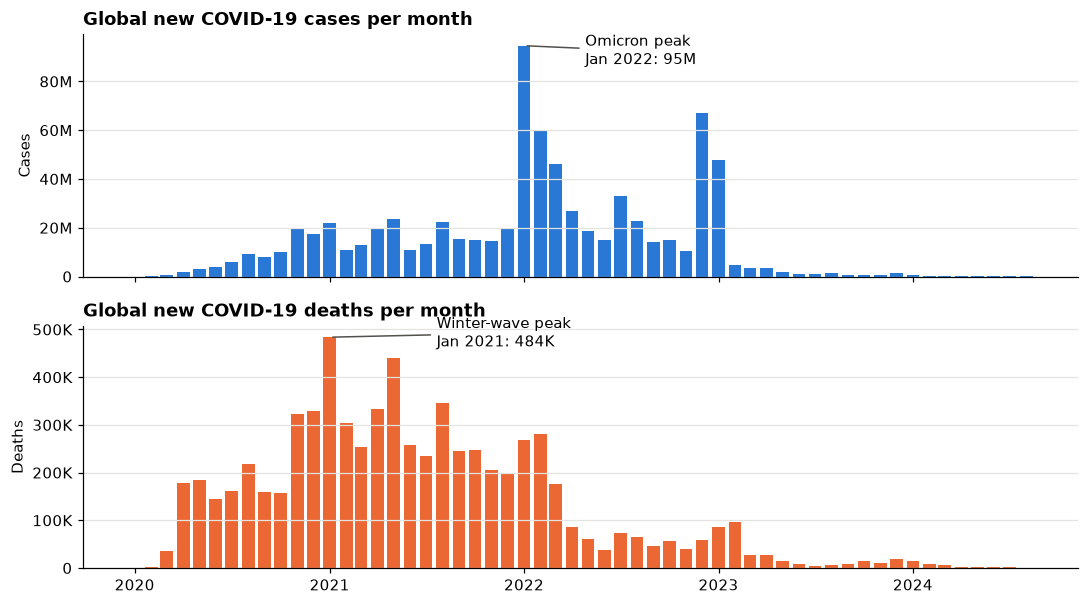

In [11]:
def fmt(x, _=None): return f"{x/1e6:.0f}M" if x >= 1e6 else (f"{x/1e3:.0f}K" if x >= 1e3 else f"{x:.0f}")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
a1.bar(monthly.month, monthly.cases, width=24, color=BLUE); a1.set_title("Global new COVID-19 cases per month"); a1.yaxis.set_major_formatter(fmt); a1.set_ylabel("Cases")
a1.annotate(f"Omicron peak\n{R['peak_cases']['month'][:3]} 2022: {pk_c.cases/1e6:.0f}M", (pk_c.month, pk_c.cases), xytext=(40, -12), textcoords="offset points", arrowprops=dict(arrowstyle="-", color=GREY))
a2.bar(monthly.month, monthly.deaths, width=24, color=ORANGE); a2.set_title("Global new COVID-19 deaths per month"); a2.yaxis.set_major_formatter(fmt); a2.set_ylabel("Deaths")
a2.annotate(f"Winter-wave peak\nJan 2021: {pk_d.deaths/1e3:.0f}K", (pk_d.month, pk_d.deaths), xytext=(70, -6), textcoords="offset points", arrowprops=dict(arrowstyle="-", color=GREY))
for a in (a1, a2): a.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig("figs/fig_monthly.png"); plt.show()

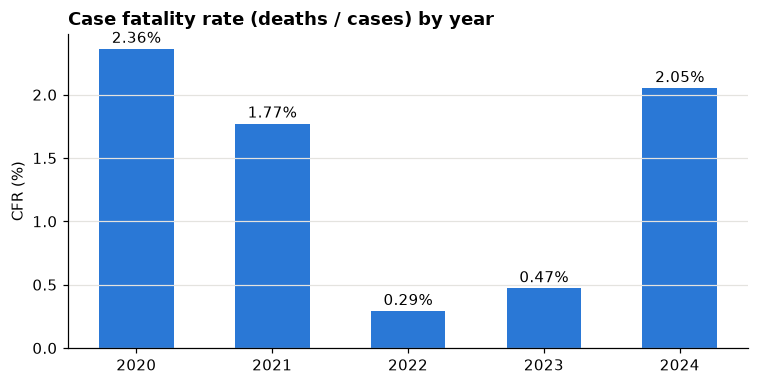

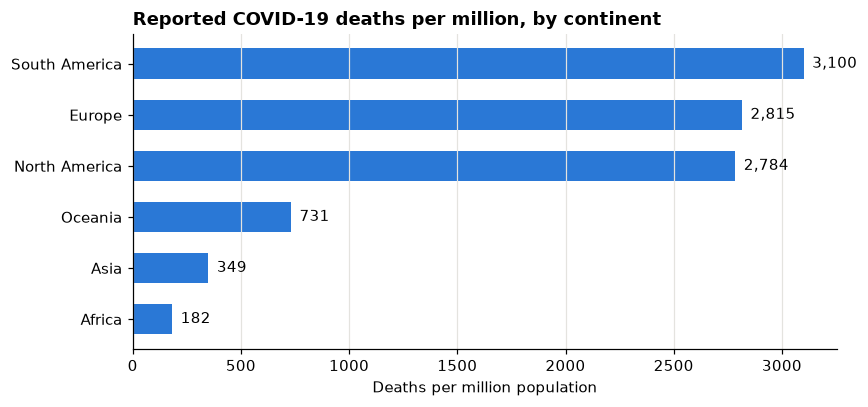

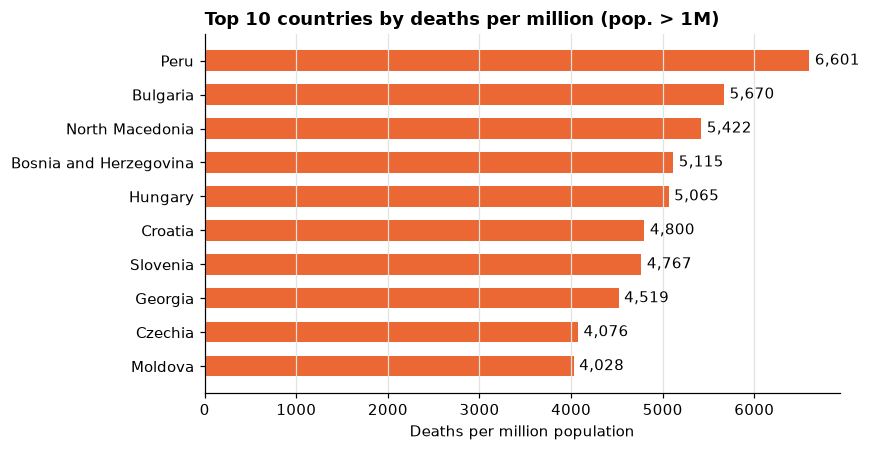

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(yearly.year.astype(str), yearly.cfr_pct, color=BLUE, width=0.55); ax.grid(axis="x", visible=False)
for i, v in enumerate(yearly.cfr_pct): ax.text(i, v + 0.05, f"{v:.2f}%", ha="center")
ax.set_title("Case fatality rate (deaths / cases) by year"); ax.set_ylabel("CFR (%)")
fig.tight_layout(); fig.savefig("figs/fig_cfr.png"); plt.show()

c = continent.sort_values("deaths_per_million")
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.barh(c.continent, c.deaths_per_million, color=BLUE, height=0.6); ax.grid(axis="y", visible=False)
for yy, v in enumerate(c.deaths_per_million): ax.text(v + 40, yy, f"{v:,.0f}", va="center")
ax.set_title("Reported COVID-19 deaths per million, by continent"); ax.set_xlabel("Deaths per million population")
fig.tight_layout(); fig.savefig("figs/fig_continent.png"); plt.show()

t10 = top10.sort_values("dpm")
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.barh(t10.location, t10.dpm, color=ORANGE, height=0.6); ax.grid(axis="y", visible=False)
for yy, v in enumerate(t10.dpm): ax.text(v + 60, yy, f"{v:,.0f}", va="center")
ax.set_title("Top 10 countries by deaths per million (pop. > 1M)"); ax.set_xlabel("Deaths per million population")
fig.tight_layout(); fig.savefig("figs/fig_top10.png"); plt.show()

## 8. Machine Learning & Deep Learning: predict next week's deaths
**Question:** if we know a country's cases and deaths for the last 4 weeks (plus a few country facts), can we predict its **deaths per million next week**? This helps hospitals plan beds and staff.

- One row = one country-week (countries with population > 1 million)
- Features: cases/M and deaths/M for this week and the 3 weeks before, % fully vaccinated, median age, GDP per capita, hospital beds
- Target: deaths per million in the **next** week
- **Time-based split:** train on weeks before July 2022, test on July 2022 – June 2023 (the model never sees the future)
- Baseline: "next week = this week" (naive guess). A model is only useful if it beats this.

In [13]:
df["week"] = df.date.dt.to_period("W").dt.start_time
w = (df.groupby(["iso_code", "location", "week"])
       .agg(cases=("new_cases", "sum"), deaths=("new_deaths", "sum"),
            vax=("people_fully_vaccinated_per_hundred", "max"), pop=("population", "first"),
            age=("median_age", "first"), gdp=("gdp_per_capita", "first"), beds=("hospital_beds_per_thousand", "first"))
       .reset_index().sort_values(["iso_code", "week"]))
w["vax"] = w.groupby("iso_code").vax.ffill().fillna(0)
w["cases_pm"] = w.cases / w["pop"] * 1e6
w["deaths_pm"] = w.deaths / w["pop"] * 1e6
g = w.groupby("iso_code")
for lag in range(4):                                   # this week (lag 0) and 3 weeks before
    w[f"cases_pm_lag{lag}"] = g.cases_pm.shift(lag)
    w[f"deaths_pm_lag{lag}"] = g.deaths_pm.shift(lag)
w["target"] = g.deaths_pm.shift(-1)                    # next week's deaths per million
FEATS = [f"cases_pm_lag{l}" for l in range(4)] + [f"deaths_pm_lag{l}" for l in range(4)] + ["vax", "age", "gdp", "beds"]
w = w[(w["pop"] > 1e6) & (w.week >= "2020-03-01") & (w.week < "2023-07-01")].dropna(subset=FEATS + ["target"])

train, test = w[w.week < "2022-07-01"], w[w.week >= "2022-07-01"]
R["ml_rows"], R["ml_countries"], R["ml_train"], R["ml_test"] = len(w), w.iso_code.nunique(), len(train), len(test)
print(f"{len(w):,} country-weeks from {w.iso_code.nunique()} countries | train {len(train):,} | test {len(test):,}")

def prep(d):                                           # log scale for skewed counts
    X = d[FEATS].copy()
    for c in FEATS[:8]: X[c] = np.log1p(X[c].clip(lower=0))
    X["gdp"] = np.log10(X["gdp"])
    return X
Xtr, Xte = prep(train), prep(test)
ytr, yte = np.log1p(train.target), test.target.values

23,664 country-weeks from 136 countries | train 16,592 | test 7,072


In [14]:
results, preds = {}, {}
def score(name, p):
    p = np.clip(p, 0, None); preds[name] = p
    results[name] = {"MAE": round(mean_absolute_error(yte, p), 3), "R2": round(r2_score(yte, p), 3)}
    print(f"{name:22s} MAE = {results[name]['MAE']:.3f} deaths/M   R2 = {results[name]['R2']:.3f}")

score("Naive (same as now)", test.deaths_pm_lag0.values)

t = time.time(); lr = LinearRegression().fit(Xtr, ytr); R["lr_train_s"] = round(time.time() - t, 2)
score("Linear Regression", np.expm1(lr.predict(Xte)))

t = time.time(); rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42).fit(Xtr, ytr)
R["rf_train_s"] = round(time.time() - t, 2)
score("Random Forest", np.expm1(rf.predict(Xte)))

Naive (same as now)    MAE = 0.657 deaths/M   R2 = 0.683
Linear Regression      MAE = 0.589 deaths/M   R2 = 0.777


Random Forest          MAE = 0.649 deaths/M   R2 = 0.740


In [15]:
# Deep Learning: a small neural network (Keras)
tf.keras.utils.set_random_seed(42)
scaler = StandardScaler().fit(Xtr)
nn = tf.keras.Sequential([
    tf.keras.Input(shape=(len(FEATS),)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)])
nn.compile(optimizer="adam", loss="mse", metrics=["mae"])
nn.summary()
t = time.time()
hist = nn.fit(scaler.transform(Xtr), ytr.values, validation_split=0.2, epochs=60, batch_size=128, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
R["nn_train_s"] = round(time.time() - t, 2); R["nn_epochs"] = len(hist.history["loss"]); R["nn_params"] = int(nn.count_params())
print("epochs run:", R["nn_epochs"])
score("Neural Network (Keras)", np.expm1(nn.predict(scaler.transform(Xte), verbose=0).ravel()))
R["models"] = results

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

epochs run: 16


Neural Network (Keras) MAE = 0.621 deaths/M   R2 = 0.763


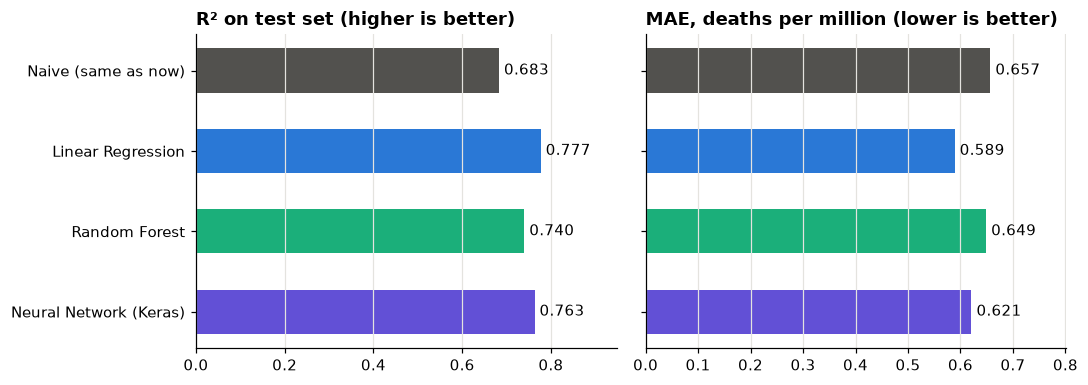

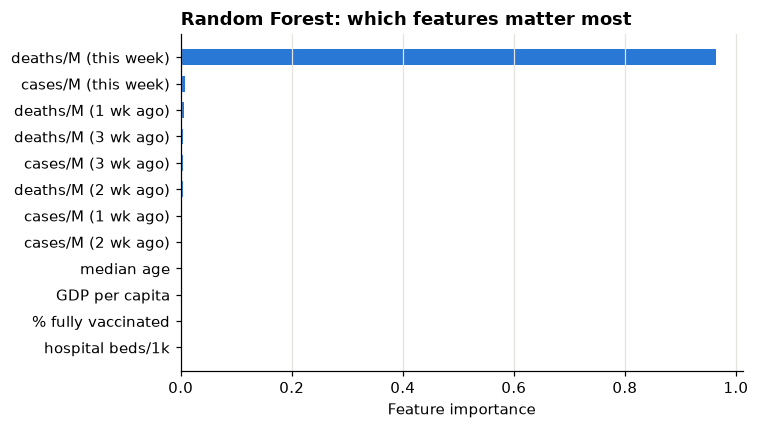

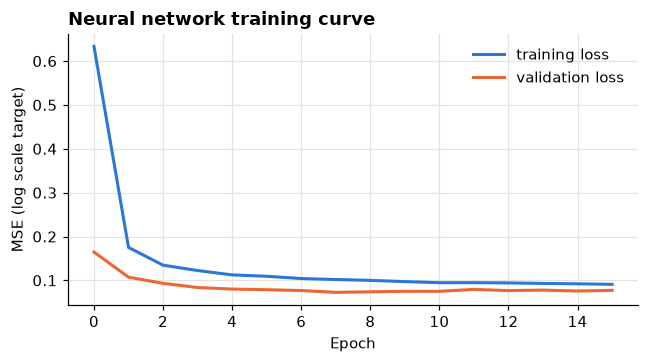

In [16]:
names = list(results); cols = [GREY, BLUE, AQUA, VIOLET]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, key, title in [(a1, "R2", "R² on test set (higher is better)"), (a2, "MAE", "MAE, deaths per million (lower is better)")]:
    vals = [results[n][key] for n in names]
    ax.barh(names, vals, color=cols, height=0.55); ax.grid(axis="y", visible=False); ax.invert_yaxis(); ax.set_title(title)
    for i, v in enumerate(vals): ax.text(v, i, f" {v:.3f}", va="center")
    ax.set_xlim(0, max(vals) * 1.22)
a2.set_yticklabels([])
fig.tight_layout(); fig.savefig("figs/fig_models.png"); plt.show()

imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values()
nice = {f"cases_pm_lag{l}": f"cases/M ({'this week' if l == 0 else f'{l} wk ago'})" for l in range(4)}
nice.update({f"deaths_pm_lag{l}": f"deaths/M ({'this week' if l == 0 else f'{l} wk ago'})" for l in range(4)})
nice.update({"vax": "% fully vaccinated", "age": "median age", "gdp": "GDP per capita", "beds": "hospital beds/1k"})
R["rf_importance"] = {nice[k]: round(float(v), 3) for k, v in imp.sort_values(ascending=False).items()}
fig, ax = plt.subplots(figsize=(7, 4)); ax.barh([nice[i] for i in imp.index], imp.values, color=BLUE, height=0.6); ax.grid(axis="y", visible=False)
ax.set_title("Random Forest: which features matter most"); ax.set_xlabel("Feature importance")
fig.tight_layout(); fig.savefig("figs/fig_importance.png"); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(hist.history["loss"], color=BLUE, lw=2, label="training loss"); ax.plot(hist.history["val_loss"], color=ORANGE, lw=2, label="validation loss")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (log scale target)"); ax.set_title("Neural network training curve"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figs/fig_nn_loss.png"); plt.show()

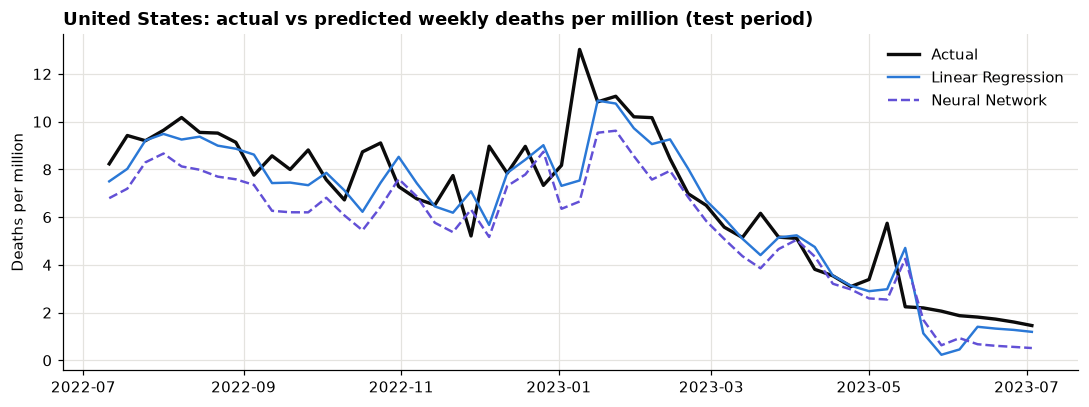

saved


In [17]:
# actual vs predicted for the country with the most total deaths in the test period
te = test.assign(**{k: v for k, v in preds.items()})
top = te.assign(abs_deaths=te.target * te["pop"]).groupby("location").abs_deaths.sum().idxmax(); R["example_country"] = top
d = te[te.location == top]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(d.week + pd.Timedelta(days=7), d.target, color="#0b0b0b", lw=2.2, label="Actual")
ax.plot(d.week + pd.Timedelta(days=7), d["Linear Regression"], color=BLUE, lw=1.6, label="Linear Regression")
ax.plot(d.week + pd.Timedelta(days=7), d["Neural Network (Keras)"], color=VIOLET, lw=1.6, ls="--", label="Neural Network")
ax.set_title(f"{top}: actual vs predicted weekly deaths per million (test period)"); ax.set_ylabel("Deaths per million"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figs/fig_actual_vs_pred.png"); plt.show()

with open("output/results.json", "w") as f: json.dump(R, f, indent=2, default=str)
monthly.to_csv("output/monthly_global.csv", index=False); continent.to_csv("output/continent_summary.csv", index=False)
top10.to_csv("output/top10_deaths_per_million.csv", index=False); pd.DataFrame(results).T.to_csv("output/model_results.csv")
con.close(); print("saved")

## 9. Conclusion
- Cleaned 429K records, stored them in a SQL database and analysed them with SQL queries.
- Omicron (Jan 2022) was the biggest wave by cases, but the case-fatality rate fell sharply from 2020 to 2022.
- South America and Eastern/Central Europe had the highest reported deaths per million.
- All three models beat the naive guess; the simple Linear Regression was as good as the neural network — a bigger model is not always better.